# 대출 채무불이행 확률 예측 (Loan Default Probability)

대출 데이터를 이용해 대출이 **완납(Fully Paid)** 될지 **대손상각(Charged Off, 부도)** 될지를 예측하는 분류 사례

<a id='0'></a>
# 1. 문제 정의

* 대출 정보(금액, 금리, 등급, 신용점수 등)로부터 대출의 최종 상태(완납 vs 대손상각)를 예측하는 **이진 분류** 문제
* 여러 분류 모델을 비교하고, 가장 우수한 모델(GBM)을 튜닝한 뒤 검증 데이터로 성능과 특성 중요도를 확인

<a id='1'></a>
# 2. 시작하기 - 파이썬 패키지와 데이터 불러오기

<a id='1.1'></a>
## 2.1. 파이썬 패키지 불러오기

In [1]:
# Load libraries
import numpy as np
import pandas as pd
from matplotlib import pyplot
from pandas import read_csv, set_option
from pandas.plotting import scatter_matrix
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score


#Libraries for Saving the Model
from pickle import dump
from pickle import load

<a id='1.2'></a>
## 2.2. 데이터 불러오기

In [ ]:
# load dataset
loans = pd.read_csv('LoansData_sample.csv.gz', compression='gzip', encoding='utf-8')
#loans = pd.read_csv('LoansData.csv.gz', compression='gzip', low_memory=True) #Use this for the actual data

In [ ]:
dataset = loans

In [ ]:
#Diable the warnings
import warnings
warnings.filterwarnings('ignore')

In [ ]:
type(dataset)

pandas.DataFrame

<a id='2'></a>
## 3. 데이터 준비 및 특성 선택

<a id='2.1'></a>
## 3.1. 예측 변수 준비

In [ ]:
# We're going to try to predict the loan_status variable. What are the value counts for this variable
dataset['loan_status'].value_counts(dropna=False)

loan_status
Fully Paid            69982
Charged Off           16156
Current               12726
Late (31-120 days)      730
In Grace Period         264
Late (16-30 days)       139
Default                   3
Name: count, dtype: int64

In [ ]:
# [수정] .copy()로 복사본을 만들어 SettingWithCopy 경고/오류 방지
dataset = dataset.loc[dataset['loan_status'].isin(['Fully Paid', 'Charged Off'])].copy()

dataset['loan_status'].value_counts(dropna=False)

dataset['loan_status'].value_counts(normalize=True, dropna=False)

loan_status
Fully Paid     0.812441
Charged Off    0.187559
Name: proportion, dtype: float64

In [ ]:
dataset['charged_off'] = (dataset['loan_status'] == 'Charged Off').apply(np.uint8)
dataset.drop('loan_status', axis=1, inplace=True)

<a id='2.2'></a>
## 3.2. 특성 선택 - 특성 공간 제한

<a id='2.2.1'></a>
### 3.2.1. 결측치가 많은 특성 제거

먼저 각 특성의 결측치 비율을 계산

In [ ]:
missing_fractions = dataset.isnull().mean().sort_values(ascending=False)

missing_fractions.head(10)

member_id                           1.0
sec_app_chargeoff_within_12_mths    1.0
sec_app_num_rev_accts               1.0
sec_app_open_act_il                 1.0
sec_app_revol_util                  1.0
annual_inc_joint                    1.0
max_bal_bc                          1.0
inq_last_12m                        1.0
dti_joint                           1.0
verification_status_joint           1.0
dtype: float64

In [ ]:
drop_list = sorted(list(missing_fractions[missing_fractions > 0.3].index))
print(drop_list)

['all_util', 'annual_inc_joint', 'debt_settlement_flag_date', 'deferral_term', 'desc', 'dti_joint', 'hardship_amount', 'hardship_dpd', 'hardship_end_date', 'hardship_last_payment_amount', 'hardship_length', 'hardship_loan_status', 'hardship_payoff_balance_amount', 'hardship_reason', 'hardship_start_date', 'hardship_status', 'hardship_type', 'il_util', 'inq_fi', 'inq_last_12m', 'max_bal_bc', 'member_id', 'mths_since_last_delinq', 'mths_since_last_major_derog', 'mths_since_last_record', 'mths_since_rcnt_il', 'mths_since_recent_bc_dlq', 'mths_since_recent_revol_delinq', 'next_pymnt_d', 'open_acc_6m', 'open_act_il', 'open_il_12m', 'open_il_24m', 'open_rv_12m', 'open_rv_24m', 'orig_projected_additional_accrued_interest', 'payment_plan_start_date', 'revol_bal_joint', 'sec_app_chargeoff_within_12_mths', 'sec_app_collections_12_mths_ex_med', 'sec_app_earliest_cr_line', 'sec_app_fico_range_high', 'sec_app_fico_range_low', 'sec_app_inq_last_6mths', 'sec_app_mort_acc', 'sec_app_mths_since_last_ma

In [ ]:
len(drop_list)

58

In [ ]:
dataset.drop(labels=drop_list, axis=1, inplace=True)
dataset.shape

(86138, 93)

<a id='2.2.2'></a>
### 3.2.2. 직관(도메인 지식)에 기반한 특성 제거

In [ ]:
print(sorted(dataset.columns))

['Unnamed: 0', 'acc_now_delinq', 'acc_open_past_24mths', 'addr_state', 'annual_inc', 'application_type', 'avg_cur_bal', 'bc_open_to_buy', 'bc_util', 'charged_off', 'chargeoff_within_12_mths', 'collection_recovery_fee', 'collections_12_mths_ex_med', 'debt_settlement_flag', 'delinq_2yrs', 'delinq_amnt', 'disbursement_method', 'dti', 'earliest_cr_line', 'emp_length', 'emp_title', 'fico_range_high', 'fico_range_low', 'funded_amnt', 'funded_amnt_inv', 'grade', 'hardship_flag', 'home_ownership', 'id', 'initial_list_status', 'inq_last_6mths', 'installment', 'int_rate', 'issue_d', 'last_credit_pull_d', 'last_fico_range_high', 'last_fico_range_low', 'last_pymnt_amnt', 'last_pymnt_d', 'loan_amnt', 'mo_sin_old_il_acct', 'mo_sin_old_rev_tl_op', 'mo_sin_rcnt_rev_tl_op', 'mo_sin_rcnt_tl', 'mort_acc', 'mths_since_recent_bc', 'mths_since_recent_inq', 'num_accts_ever_120_pd', 'num_actv_bc_tl', 'num_actv_rev_tl', 'num_bc_sats', 'num_bc_tl', 'num_il_tl', 'num_op_rev_tl', 'num_rev_accts', 'num_rev_tl_bal_

유지할 특성 목록은 다음과 같습니다:

In [ ]:
keep_list = ['charged_off','funded_amnt','addr_state', 'annual_inc', 'application_type', 'dti', 'earliest_cr_line', 'emp_length', 'emp_title', 'fico_range_high', 'fico_range_low', 'grade', 'home_ownership', 'id', 'initial_list_status', 'installment', 'int_rate', 'loan_amnt', 'loan_status', 'mort_acc', 'open_acc', 'pub_rec', 'pub_rec_bankruptcies', 'purpose', 'revol_bal', 'revol_util', 'sub_grade', 'term', 'title', 'total_acc', 'verification_status', 'zip_code','last_pymnt_amnt','num_actv_rev_tl', 'mo_sin_rcnt_rev_tl_op','mo_sin_old_rev_tl_op',"bc_util","bc_open_to_buy","avg_cur_bal","acc_open_past_24mths" ]

len(keep_list)

40

In [ ]:
drop_list = [col for col in dataset.columns if col not in keep_list]

dataset.drop(labels=drop_list, axis=1, inplace=True)

dataset.shape

(86138, 39)

<a id='2.2.3'></a>
### 3.2.3. 상관관계 기반 특성 제거

목표 변수(`charged_off`)와의 상관계수 절댓값이 0.03 미만인 특성을 제거

In [ ]:
correlation = dataset.corr(numeric_only=True)
correlation_chargeOff = abs(correlation['charged_off'])

In [ ]:
correlation_chargeOff.sort_values(ascending=False)

charged_off              1.000000
last_pymnt_amnt          0.319081
int_rate                 0.282825
dti                      0.123108
fico_range_low           0.121892
fico_range_high          0.121891
acc_open_past_24mths     0.105989
bc_open_to_buy           0.080077
bc_util                  0.077744
avg_cur_bal              0.071977
num_actv_rev_tl          0.071185
revol_util               0.066188
loan_amnt                0.060818
funded_amnt              0.060818
mort_acc                 0.057858
annual_inc               0.050349
mo_sin_old_rev_tl_op     0.049426
mo_sin_rcnt_rev_tl_op    0.048839
open_acc                 0.039430
installment              0.032847
revol_bal                0.021714
pub_rec                  0.016023
pub_rec_bankruptcies     0.015815
total_acc                0.005804
id                       0.002221
Name: charged_off, dtype: float64

In [ ]:
drop_list_corr = sorted(list(correlation_chargeOff[correlation_chargeOff < 0.03].index))
print(drop_list_corr)

['id', 'pub_rec', 'pub_rec_bankruptcies', 'revol_bal', 'total_acc']


In [ ]:
dataset.drop(labels=drop_list_corr, axis=1, inplace=True)
dataset.shape

(86138, 34)

<a id='3'></a>
# 4. 특성 엔지니어링 및 탐색적 분석

In [ ]:
#Descriptive Statistics
dataset.describe()

,loan_amnt,funded_amnt,int_rate,installment,annual_inc,dti,fico_range_low,fico_range_high,open_acc,revol_util,last_pymnt_amnt,acc_open_past_24mths,avg_cur_bal,bc_open_to_buy,bc_util,mo_sin_old_rev_tl_op,mo_sin_rcnt_rev_tl_op,mort_acc,num_actv_rev_tl,charged_off
count,86138.000000,86138.000000,86138.000000,86138.000000,8.613800e+04,86138.000000,86138.000000,86138.000000,86138.000000,86094.000000,86138.000000,86138.000000,86138.000000,85142.000000,85089.000000,86138.000000,86138.000000,86138.000000,86138.000000,86138.000000
mean,14106.526446,14106.526446,13.002360,430.737187,7.384311e+04,18.532747,692.462966,696.463024,11.746453,54.582777,4757.453184,4.594732,13066.638371,8942.506507,63.808959,183.524333,12.796896,1.748880,5.762358,0.187559
std,8391.139221,8391.139221,4.397419,251.653139,5.929352e+04,8.538247,29.731549,29.731848,5.433122,23.515901,6466.767327,3.070996,16232.739293,14100.186250,27.051347,93.266430,16.224586,2.091488,3.224598,0.390362
min,1000.000000,1000.000000,6.000000,30.420000,4.000000e+03,0.000000,660.000000,664.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000
25%,7800.000000,7800.000000,9.490000,248.480000,4.500000e+04,12.070000,670.000000,674.000000,8.000000,37.200000,358.522500,2.000000,3010.000000,1087.000000,44.100000,118.000000,3.000000,0.000000,3.000000,0.000000
50%,12000.000000,12000.000000,12.990000,370.480000,6.247372e+04,17.950000,685.000000,689.000000,11.000000,54.900000,1241.230000,4.000000,6994.500000,3823.000000,67.700000,167.000000,8.000000,1.000000,5.000000,0.000000
75%,20000.000000,20000.000000,15.610000,568.005000,9.000000e+04,24.500000,705.000000,709.000000,14.000000,72.500000,7303.205000,6.000000,17905.000000,10588.000000,87.500000,232.000000,15.000000,3.000000,7.000000,0.000000
max,35000.000000,35000.000000,26.060000,1408.130000,7.500000e+06,39.990000,845.000000,850.000000,84.000000,180.300000,36234.440000,53.000000,447433.000000,249625.000000,255.200000,718.000000,372.000000,34.000000,38.000000,1.000000


<a id='3.1'></a>
## 4.1. 특성 분석 및 탐색

<a id='3.1.1'></a>
### 4.1.1. 범주형 특성 분석

In [ ]:
# [수정] 'id'는 3.2.3절(상관관계 기반 제거)에서 이미 삭제되어 KeyError가 발생했으므로, 남아 있는 컬럼만 조회
dataset[['emp_title','title','zip_code']].describe()

,emp_title,title,zip_code
count,81416,86138,86138
unique,32987,20,846
top,Teacher,Debt consolidation,750xx
freq,1576,52990,954


In [ ]:
#Ids are all unique and there are too many job titles and titles and zipcode,
#these column is dropped The ID is not useful for modeling.
# [수정] 이미 삭제된 컬럼('id')이 있어도 오류가 나지 않도록 errors='ignore' 추가
dataset.drop(['id','emp_title','title','zip_code'], axis=1, inplace=True, errors='ignore')

#### 특성: 대출 기간(Term)

In [ ]:
#Data Dictionary: "The number of payments on the loan. Values are in months and can be either 36 or 60.".
#The 60 Months loans are more likelely to charge off
#Convert term to integers
dataset['term'] = dataset['term'].apply(lambda s: np.int8(s.split()[0]))

In [ ]:
dataset.groupby('term')['charged_off'].value_counts(normalize=True).loc[:,1]

term
36    0.141526
60    0.354356
Name: proportion, dtype: float64

#### 특성: 재직 기간(Employment Length)

In [ ]:
# [수정] 최신 pandas에서 동작하지 않는 inplace 체인 할당 대신 대입 방식 사용
dataset['emp_length'] = dataset['emp_length'].replace('10+ years', '10 years')

dataset['emp_length'] = dataset['emp_length'].replace('< 1 year', '0 years')

def emp_length_to_int(s):
    if pd.isnull(s):
        return s
    else:
        return np.int8(s.split()[0])

dataset['emp_length'] = dataset['emp_length'].apply(emp_length_to_int)


<Axes: xlabel='emp_length'>

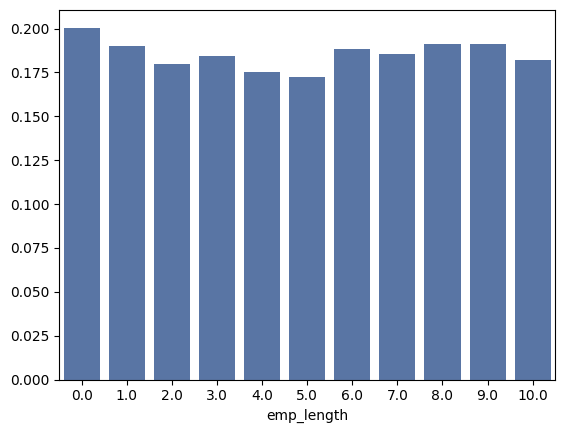

In [ ]:
charge_off_rates = dataset.groupby('emp_length')['charged_off'].value_counts(normalize=True).loc[:,1]
sns.barplot(x=charge_off_rates.index, y=charge_off_rates.values, color='#5975A4', saturation=1)

In [ ]:
dataset.drop(['emp_length'], axis=1, inplace=True)

#### 특성: 서브등급(Sub-grade)

<Axes: xlabel='sub_grade'>

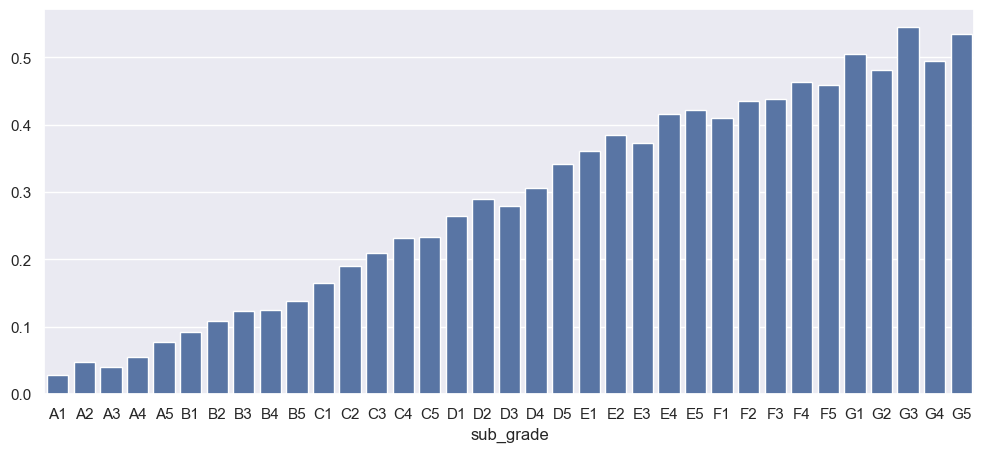

In [ ]:
charge_off_rates = dataset.groupby('sub_grade')['charged_off'].value_counts(normalize=True).loc[:,1]
sns.set(rc={'figure.figsize':(12,5)})
sns.barplot(x=charge_off_rates.index, y=charge_off_rates.values, color='#5975A4', saturation=1)


In [ ]:
dataset['earliest_cr_line'] = dataset['earliest_cr_line'].apply(lambda s: int(s[-4:]))

<a id='3.1.2'></a>
### 4.1.2. 연속형 특성 분석

#### 특성: 연소득(Annual Income)

In [ ]:
dataset[['annual_inc']].describe()

,annual_inc
count,8.613800e+04
mean,7.384311e+04
std,5.929352e+04
min,4.000000e+03
25%,4.500000e+04
50%,6.247372e+04
75%,9.000000e+04
max,7.500000e+06


In [ ]:
dataset['log_annual_inc'] = dataset['annual_inc'].apply(lambda x: np.log10(x+1))
dataset.drop('annual_inc', axis=1, inplace=True)

#### FICO 점수

In [ ]:
dataset[['fico_range_low','fico_range_high']].corr()

,fico_range_low,fico_range_high
fico_range_low,1.0,1.0
fico_range_high,1.0,1.0


In [ ]:
dataset['fico_score'] = 0.5*dataset['fico_range_low'] + 0.5*dataset['fico_range_high']

dataset.drop(['fico_range_high', 'fico_range_low'], axis=1, inplace=True)

In [ ]:
dataset['charged_off'].value_counts()

charged_off
0    69982
1    16156
Name: count, dtype: int64

<a id='3.2'></a>
## 4.2. 범주형 데이터 인코딩

In [ ]:
from sklearn.preprocessing import LabelEncoder

In [ ]:
# [수정] 최신 pandas(3.x)에서는 문자열 컬럼이 object가 아닌 'str' 타입이라 dtypes==object로는 하나도 탐지되지 않음
#        -> 숫자가 아닌 모든 컬럼을 범주형으로 간주하도록 변경
categorical_cols = dataset.select_dtypes(exclude='number').columns.tolist()

In [ ]:
categorical_cols

['grade',
 'sub_grade',
 'home_ownership',
 'verification_status',
 'purpose',
 'addr_state',
 'initial_list_status',
 'application_type']

In [ ]:
le = LabelEncoder()
# apply le on categorical feature columns
# [수정] 결측치(NaN)가 섞여 있어도 LabelEncoder가 오류 없이 동작하도록 astype(str) 적용
dataset[categorical_cols] = dataset[categorical_cols].apply(lambda col: le.fit_transform(col.astype(str)))
dataset[categorical_cols].head(10)

,grade,sub_grade,home_ownership,verification_status,purpose,addr_state,initial_list_status,application_type
0,2,10,3,1,2,40,1,0
1,0,2,1,0,1,4,1,0
2,3,15,3,1,1,21,1,0
4,2,12,3,1,2,3,0,0
5,2,12,3,1,2,26,0,0
6,1,9,1,1,3,20,0,0
7,1,8,2,2,2,40,1,0
8,2,13,3,1,1,42,0,0
9,1,8,3,0,2,18,0,0
10,1,9,3,2,2,19,0,0


In [ ]:
dataset.head(5)

,loan_amnt,funded_amnt,term,int_rate,installment,grade,sub_grade,home_ownership,verification_status,purpose,...,avg_cur_bal,bc_open_to_buy,bc_util,mo_sin_old_rev_tl_op,mo_sin_rcnt_rev_tl_op,mort_acc,num_actv_rev_tl,charged_off,log_annual_inc,fico_score
0,15000.0,15000.0,60,12.39,336.64,2,10,3,1,2,...,29828.0,9525.0,4.7,244.0,1.0,0.0,4.0,0,4.892100,752.0
1,10400.0,10400.0,36,6.99,321.08,0,2,1,0,1,...,9536.0,7599.0,41.5,290.0,1.0,1.0,9.0,1,4.763435,712.0
2,21425.0,21425.0,60,15.59,516.36,3,15,3,1,1,...,4232.0,324.0,97.8,136.0,7.0,0.0,4.0,0,4.804827,687.0
4,7650.0,7650.0,36,13.66,260.20,2,12,3,1,2,...,5857.0,332.0,93.2,148.0,8.0,0.0,4.0,1,4.698979,687.0
5,9600.0,9600.0,36,13.66,326.53,2,12,3,1,2,...,3214.0,6494.0,69.2,265.0,23.0,0.0,7.0,0,4.838855,682.0


In [ ]:
dataset.shape

(86138, 29)

<a id='3.4'></a>
## 4.3. 데이터 샘플링

In [ ]:
loanstatus_0 = dataset[dataset["charged_off"]==0]
loanstatus_1 = dataset[dataset["charged_off"]==1]
subset_of_loanstatus_0 = loanstatus_0.sample(n=5500)
subset_of_loanstatus_1 = loanstatus_1.sample(n=5500)
dataset = pd.concat([subset_of_loanstatus_1, subset_of_loanstatus_0])
dataset = dataset.sample(frac=1).reset_index(drop=True)
print("Current shape of dataset :",dataset.shape)
dataset.head()

Current shape of dataset : (11000, 29)


,loan_amnt,funded_amnt,term,int_rate,installment,grade,sub_grade,home_ownership,verification_status,purpose,...,avg_cur_bal,bc_open_to_buy,bc_util,mo_sin_old_rev_tl_op,mo_sin_rcnt_rev_tl_op,mort_acc,num_actv_rev_tl,charged_off,log_annual_inc,fico_score
0,11500.0,11500.0,36,16.99,409.95,3,17,1,0,3,...,19335.0,399.0,87.5,66.0,3.0,2.0,5.0,0,4.689140,687.0
1,11200.0,11200.0,36,13.35,379.27,2,11,2,0,7,...,19903.0,11556.0,11.1,136.0,22.0,2.0,1.0,1,4.556315,727.0
2,35000.0,35000.0,36,14.49,1204.57,2,13,3,2,2,...,7522.0,1387.0,89.3,117.0,1.0,0.0,6.0,0,5.000004,677.0
3,27575.0,27575.0,36,14.99,955.77,2,14,3,2,2,...,1375.0,15468.0,48.4,220.0,3.0,2.0,6.0,1,4.778158,692.0
4,30000.0,30000.0,60,16.29,734.18,3,16,3,2,2,...,20074.0,128.0,99.7,182.0,22.0,3.0,2.0,1,5.079185,702.0


In [ ]:
#Filling the NAs with the mean of the column.
dataset.fillna(dataset.mean(numeric_only=True), inplace=True)

,loan_amnt,funded_amnt,term,int_rate,installment,grade,sub_grade,home_ownership,verification_status,purpose,...,avg_cur_bal,bc_open_to_buy,bc_util,mo_sin_old_rev_tl_op,mo_sin_rcnt_rev_tl_op,mort_acc,num_actv_rev_tl,charged_off,log_annual_inc,fico_score
0,11500.0,11500.0,36,16.99,409.95,3,17,1,0,3,...,19335.0,399.0,87.5,66.0,3.0,2.0,5.0,0,4.689140,687.0
1,11200.0,11200.0,36,13.35,379.27,2,11,2,0,7,...,19903.0,11556.0,11.1,136.0,22.0,2.0,1.0,1,4.556315,727.0
2,35000.0,35000.0,36,14.49,1204.57,2,13,3,2,2,...,7522.0,1387.0,89.3,117.0,1.0,0.0,6.0,0,5.000004,677.0
3,27575.0,27575.0,36,14.99,955.77,2,14,3,2,2,...,1375.0,15468.0,48.4,220.0,3.0,2.0,6.0,1,4.778158,692.0
4,30000.0,30000.0,60,16.29,734.18,3,16,3,2,2,...,20074.0,128.0,99.7,182.0,22.0,3.0,2.0,1,5.079185,702.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10995,24000.0,24000.0,60,16.29,587.34,3,16,1,2,1,...,27529.0,6636.0,71.9,122.0,9.0,2.0,6.0,1,4.875067,662.0
10996,17050.0,17050.0,36,14.49,586.80,2,13,3,2,2,...,5166.0,134.0,99.4,79.0,62.0,0.0,3.0,1,4.579795,662.0
10997,5500.0,5500.0,36,12.49,183.97,1,9,3,2,2,...,2132.0,78.0,98.3,138.0,21.0,0.0,3.0,1,4.395029,667.0
10998,35000.0,35000.0,36,17.14,1250.29,3,18,3,2,10,...,871.0,34688.0,7.0,387.0,4.0,4.0,2.0,1,5.176094,682.0


<a id='4'></a>
# 5. 알고리즘 및 모델 평가

<a id='4.1'></a>
## 5.1. 학습/검증 데이터 분할

In [ ]:
# split out validation dataset for the end
Y= dataset["charged_off"]
X = dataset.loc[:, dataset.columns != 'charged_off']
validation_size = 0.2
seed = 7
X_train, X_validation, Y_train, Y_validation = train_test_split(X, Y, test_size=validation_size, random_state=seed)

In [ ]:
# dataset_temp2=dataset_temp.dropna(axis=0)
# Y_total= dataset_temp2["charged_off"]
# X_total = dataset_temp2.loc[:, dataset.columns != 'charged_off']
# X_dummy, X_validation, Y_dummy, Y_validation = train_test_split(X_total, Y_total, test_size=validation_size)

In [ ]:
dataset['charged_off'].value_counts()

charged_off
0    5500
1    5500
Name: count, dtype: int64

<a id='4.2'></a>
## 5.2. 테스트 옵션 및 평가 지표

In [ ]:
# test options for classification
num_folds = 10
seed = 7
#scoring = 'accuracy'
#scoring ='precision'
#scoring ='recall'
scoring = 'roc_auc'

<a id='4.3'></a>
## 5.3. 모델 및 알고리즘 비교

### 분류 모델

In [ ]:
# spot check the algorithms
models = []
models.append(('LR', LogisticRegression()))
models.append(('LDA', LinearDiscriminantAnalysis()))
models.append(('KNN', KNeighborsClassifier()))
models.append(('CART', DecisionTreeClassifier()))
models.append(('NB', GaussianNB()))
#Neural Network
models.append(('NN', MLPClassifier()))
#Ensable Models
# Boosting methods
models.append(('AB', AdaBoostClassifier()))
models.append(('GBM', GradientBoostingClassifier()))
# Bagging methods
models.append(('RF', RandomForestClassifier()))
models.append(('ET', ExtraTreesClassifier()))

### K-겹 교차 검증(K-fold Cross Validation)

In [ ]:
results = []
names = []
for name, model in models:
    # [수정] scikit-learn 0.24 이상에서는 random_state를 쓰려면 shuffle=True가 필요(없으면 ValueError)
    kfold = KFold(n_splits=num_folds, shuffle=True, random_state=seed)
    cv_results = cross_val_score(model, X_train, Y_train, cv=kfold, scoring=scoring)
    results.append(cv_results)
    names.append(name)
    msg = "%s: %f (%f)" % (name, cv_results.mean(), cv_results.std())
    print(msg)

LR: 0.901947 (0.007887)
LDA: 0.903287 (0.009524)
KNN: 0.813589 (0.012270)
CART: 0.804373 (0.014487)
NB: 0.899019 (0.006715)
NN: 0.879509 (0.014142)
AB: 0.927372 (0.007646)
GBM: 0.938112 (0.005293)
RF: 0.929665 (0.005915)
ET: 0.919105 (0.006132)


### 알고리즘 비교

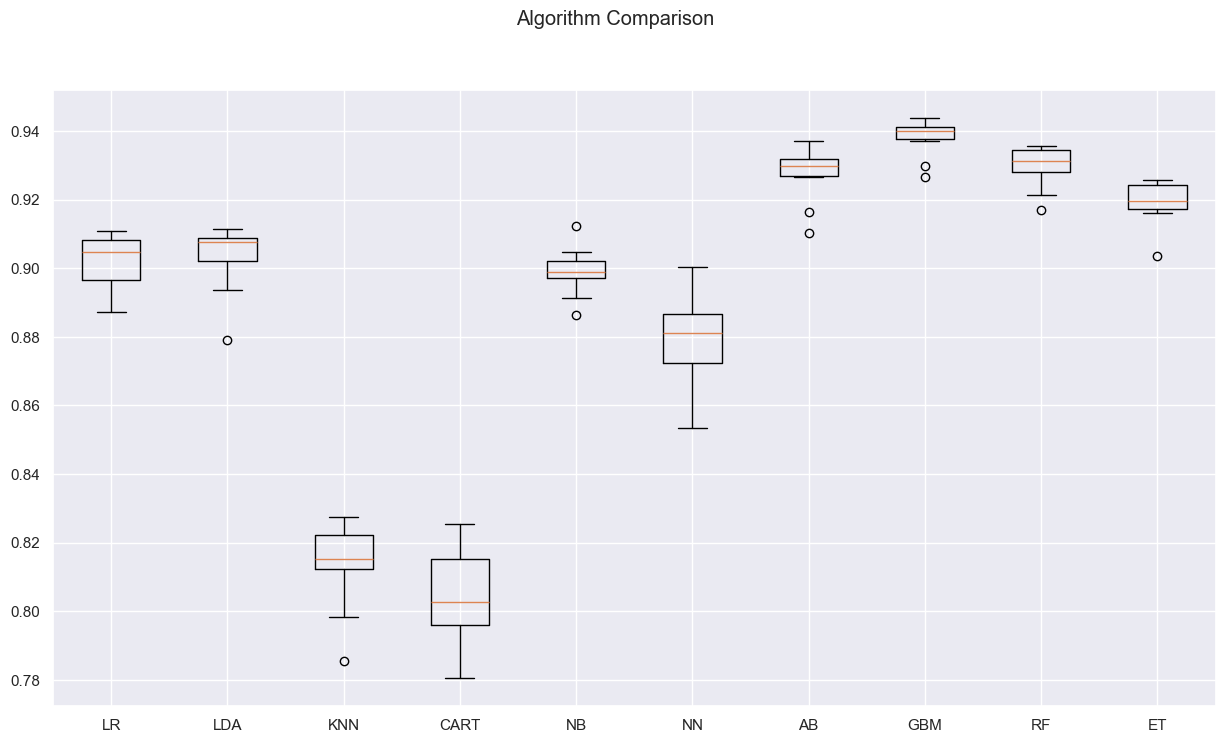

In [ ]:
# compare algorithms
fig = pyplot.figure()
fig.suptitle('Algorithm Comparison')
ax = fig.add_subplot(111)
pyplot.boxplot(results)
ax.set_xticklabels(names)
fig.set_size_inches(15,8)
pyplot.show()

<a id='5'></a>
# 6. 모델 튜닝 및 그리드 서치

GBM이 가장 우수한 모델이므로, 이 단계에서 GBM에 대해 그리드 서치를 수행합니다.

In [ ]:
# Grid Search: GradientBoosting Tuning
'''
n_estimators : int (default=100)
    The number of boosting stages to perform.
    Gradient boosting is fairly robust to over-fitting so a large number usually results in better performance.
max_depth : integer, optional (default=3)
    maximum depth of the individual regression estimators.
    The maximum depth limits the number of nodes in the tree.
    Tune this parameter for best performance; the best value depends on the interaction of the input variables.

'''
n_estimators = [20,180]
max_depth= [3,5]
param_grid = dict(n_estimators=n_estimators, max_depth=max_depth)
model = GradientBoostingClassifier()
# [수정] shuffle=True 추가 (random_state 사용 시 필수)
kfold = KFold(n_splits=num_folds, shuffle=True, random_state=seed)
grid = GridSearchCV(estimator=model, param_grid=param_grid, scoring=scoring, cv=kfold)
grid_result = grid.fit(X_train, Y_train)

#Print Results
print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))
means = grid_result.cv_results_['mean_test_score']
stds = grid_result.cv_results_['std_test_score']
params = grid_result.cv_results_['params']
ranks = grid_result.cv_results_['rank_test_score']
for mean, stdev, param, rank in zip(means, stds, params, ranks):
    print("#%d %f (%f) with: %r" % (rank, mean, stdev, param))

<a id='6'></a>
# 7. 모델 확정

<a id='6.1'></a>
## 7.1. 테스트(검증) 데이터셋 결과

In [ ]:
# prepare model
model = GradientBoostingClassifier(max_depth= 5, n_estimators= 180)
model.fit(X_train, Y_train)

In [ ]:
# estimate accuracy on validation set
predictions = model.predict(X_validation)
print(accuracy_score(Y_validation, predictions))
print(confusion_matrix(Y_validation, predictions))
print(classification_report(Y_validation, predictions))

In [ ]:
df_cm = pd.DataFrame(confusion_matrix(Y_validation, predictions), columns=np.unique(Y_validation), index = np.unique(Y_validation))
df_cm.index.name = 'Actual'
df_cm.columns.name = 'Predicted'
sns.heatmap(df_cm, cmap="Blues", annot=True,annot_kws={"size": 16})# font sizes

<a id='6.2'></a>
## 7.2. 변수 직관 / 특성 중요도


In [ ]:
print(model.feature_importances_) #use inbuilt class feature_importances of tree based classifiers
#plot graph of feature importances for better visualization
feat_importances = pd.Series(model.feature_importances_, index=X.columns)
feat_importances.nlargest(10).plot(kind='barh')
pyplot.show()